# Module 6 — Generation

Part of the RAG Playbook. Program and progress: [CURRICULUM.md](CURRICULUM.md).

## Why you're here: what this module is for

**Where this module starts**
- RAG (retrieval-augmented generation) answers a question in two steps:
  1. A search program finds the few texts in a collection that match the question.
  2. A language model, the kind of program behind chat assistants, reads those texts and writes the answer.
- A RAG system is built from five parts:
  1. Chunk: split each document into short pieces, called chunks
  2. Embed: turn each chunk into an embedding, a list of numbers that an embedding model makes from a text, so that texts with similar meaning get similar embeddings
  3. Store: keep every chunk's embedding in one table
  4. Retrieve: for each question, return the chunks that match it best
  5. **Generate**: the language model reads those chunks and writes the answer
- Everything the language model gets, the question included, is called the prompt. The language model reads the prompt at the moment it is asked, and writes its answer from it.
- The language model in this module is llama3.2:3b, a small, free model that runs on this computer. It is fixed: the module does not change or retrain it. So the prompt is the only thing left to change in part 5, and the analyst decides what it says.

**This module's point:** it builds part 5, generate, and compares two prompts on the same questions and the same chunks:
- *no rules*: the chunks the search returned, the question, and "Answer in one or two sentences."
- *rules*: the same text, plus three rules for the answer.

The question is what the three rules change in the answers.

**The three rules**
1. Use only the chunks.
2. After each sentence of the answer, write the numbers of the chunks it comes from in square brackets, such as [2]. This is called citing.
3. If the chunks do not hold the answer, reply only *"Not enough information."*

<u>Note</u>: parts 1 to 4 are fixed in this module, the same for both prompts:
- Part 1, chunk: each news article is split into its paragraphs, one chunk per paragraph. Compared with one sentence per chunk, a paragraph keeps a sentence together with the sentences around it, and those can hold words the language model needs to understand the sentence, such as the name of the company it is about.
- Part 2, embed: an existing embedding model, nomic-embed-text.
- Part 3, store: has no setting to choose.
- Part 4, retrieve: hybrid search. It combines two rankings of the chunks: a meaning search, which compares the question's embedding with each chunk's embedding, and a keyword search, which scores the words a chunk shares with the question. Each chunk gets a hybrid score = 1 / (60 + its rank in the meaning search) + 1 / (60 + its rank in the keyword search), and the chunks are ranked by that score. The chunk at rank 1 is always returned, whatever its length. The chunks after it are added from rank 2 down while the words of all returned chunks stay at or below 400 in total, a number chosen for this module, so every question's prompt holds about the same amount of text. A chunk is never cut, so when the rank-1 chunk alone holds more than 400 words, it is returned alone, over the 400-word limit.

**What this module measures**

The test questions come from a public dataset called MultiHop-RAG, of questions about news articles. They are of two kinds:
1. Questions with an answer in the articles. For each, the dataset gives the correct answer and lists the sentences in the articles that support it.
2. Questions with no answer in the articles. For each, the dataset's correct answer is *"Insufficient information."*

Every answer, from each prompt, gets two checks:
1. Its ruling: *right*, *did not answer*, or *wrong*.
2. Its citations: whether it cites chunk numbers, and whether a cited chunk holds a sentence the dataset lists for the question.

The module runs five steps:
1. Build the two prompts for one question, and print them.
2. Answer the questions with an answer, with each prompt, and rule on the answers.
3. Answer the questions with no answer, with each prompt, and rule on the answers.
4. Check the citations.
5. Show two example answers from the *rules* prompt, one right and one wrong: can a user tell them apart?

**Two tags in this module**
- **[in real life]** marks a step that happens in a real system: the analyst testing the prompts before the system goes live, or a user reading an answer once it is live. A live user's question comes with no correct answer, so the analyst tests the prompts on questions that do have one.
- **[only in this module]** marks a step that a real system would not do, chosen to make this module simpler or faster.

**What this module produces**
1. The two prompts (*no rules* and *rules*), side by side.
2. The rulings on each prompt's answers, for both kinds of question (with and without an answer).
3. Citation checks: how many answers cite chunks, how many cite only chunks that are in the prompt, and how many *rules* right answers cite a chunk holding a supporting sentence.
4. Two example answers from the *rules* prompt, one right and one wrong, each with the chunks it cites.

## From the curriculum

> ## <u>Module 6 — Generation</u>
>
> **Concepts**
> - Building the prompt: the question, the retrieved chunks, and the rules
> - Grounding: answering only from the retrieved chunks
> - Citing: each claim names the chunk it came from
> - Saying "not enough information" when the chunks do not hold the answer
>
> **Worked example:** answers built from the retrieved chunks, with their sources.

## Lesson

### The prompt

The prompt holds three pieces, in this order:
1. The chunks the search returned, each with its number in square brackets: [1] for the chunk ranked first, [2] for the second, and so on.
2. The question.
3. The instructions: how to answer.

The language model may also know some of the same news from its training text: the text it learned from, long before the question.

### Why each rule

1. **Use only the chunks**, called grounding. An answer from training text cannot be checked against the collection, and may be out of date or made up. An answer is grounded when every claim in it comes from the chunks.
2. **Cite the chunk numbers.** A reader of the answer can open chunk [2] and check the claim against it. A claim whose cited chunk does not hold it shows the answer is not grounded.
3. **Say *"Not enough information"* when the chunks do not hold the answer.** The chunks can miss the answer in two ways: the search did not return the chunks that hold it, or the collection never held it. Without this rule, the language model can fill the gap with a guess, written as plainly as a right answer.

The three rules are instructions, not locks: the language model can still break them. Only checking the answers shows how often it follows them.

### How an answer is ruled on

A **declining phrase** is a phrase that means "the chunks lack the answer", such as *"not mentioned"* or *"Not enough information"*. The dataset writes the correct answer of a question with no answer as *"Insufficient information."*, and rule 3 asks for *"Not enough information"*: both are declining phrases, and the ruling accepts any declining phrase. The list printed by the next code cell was collected by reading this module's answers: each phrase is one way the answers declined. So the list fits these answers and may miss a phrase in other answers; the hand check, described below, reads every answer anyway.

Every answer gets one ruling. The correct answer differs by kind of question, so the rules for the ruling do too. A **candidate** is a specific answer to the question, such as a name or a letter, even one offered as a guess. In each table, the rows are checked from the top down, and the first row that fits gives the ruling.

Questions with an answer in the articles:

| Ruling | Rule |
|---|---|
| *right* | the dataset's correct answer appears in the answer, ignoring capital letters |
| *did not answer* | the answer holds a declining phrase and offers no candidate |
| *wrong* | anything else |

So an answer that holds the correct answer and also a declining phrase counts as *right*.

Questions with no answer in the articles. Here the correct answer is to decline:

| Ruling | Rule |
|---|---|
| *did not answer* | the answer holds a declining phrase and offers no candidate, such as a name or a letter |
| *wrong* | anything else, such as an answer that offers a candidate, even with *"likely"* in front of it or *"Not enough information"* after it |

A program can find a declining phrase, but it cannot tell whether the answer also offers a candidate, as in *"the text does not mention the country, but it is likely Brazil"*. A broad phrase such as *"cannot"* can also match an answer that offers one. So every answer was also read one by one while this module was built: the hand check. Among the questions with no answer, every answer the program ruled *wrong* offers a candidate, so the hand check kept those rulings. The code prints each ruling the hand check changed, with its reason. The tables of rulings count the ruling after the hand check.

### How a citation is checked

An answer cites when it holds at least one chunk number in square brackets, such as [2] or [1, 3]. Each citing answer gets two checks:
- Every cited number is a chunk in the prompt: from 1 to the number of chunks the search returned. Chunk numbers exist only in the prompt, so a number outside that range points to a chunk that does not exist: the language model made the number up.
- For a question with an answer: at least one cited chunk holds a sentence the dataset lists for the question.

This module checks only whether an answer cites, not whether each of its sentences does.

The code below loads the tools, sets the two prompts, and prints the declining phrases. `common` is this playbook's shared helper file: it loads the data, calls the models, and prints tables.

In [1]:
import re
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import common
from common import show, RULING_COLORS

BUDGET = 400                                       # words returned per question (part 4)
K1, B, RRF = 1.2, 0.75, 60                         # standard settings, not chosen here: K1 and B of BM25, RRF = the 60 in hybrid search
SAMPLE = 40                                        # questions of each kind, chosen for run time
MAX_TOKENS = 120                                   # longest answer, in tokens (word-pieces, about 3/4 of a word each), chosen for run time
tidy = lambda text: " ".join(text.split())       # one space between words, no line breaks

PROMPTS = {
    "no rules": ("Here are chunks of news articles:\n\n{chunks}\n\nQuestion: {question}\n"
                 "Answer in one or two sentences."),
    "rules": ("Here are chunks of news articles:\n\n{chunks}\n\nQuestion: {question}\n"
              "Answer in one or two sentences, using only the chunks above. "
              "After each sentence of your answer, write the numbers of the chunks it comes from in square brackets, such as [2]. "
              "If the chunks do not hold the answer, reply only: Not enough information.")}

NO_ANSWER = ["not enough information", "don't know", "do not know", "not aware", "no information", "unable to",
             "cannot", "can't", "couldn't find", "could not find", "not sure", "i'm sorry", "not mentioned",
             "not specified", "does not mention", "do not mention", "no mention", "does not contain",
             "not explicitly", "not provide", "not present", "no indication", "not possible", "insufficient information"]
print("Declining phrases:")
for i in range(0, len(NO_ANSWER), 6):
    print("  " + ", ".join(f'"{p}"' for p in NO_ANSWER[i:i + 6]))

Declining phrases:
  "not enough information", "don't know", "do not know", "not aware", "no information", "unable to"
  "cannot", "can't", "couldn't find", "could not find", "not sure", "i'm sorry"
  "not mentioned", "not specified", "does not mention", "do not mention", "no mention", "does not contain"
  "not explicitly", "not provide", "not present", "no indication", "not possible", "insufficient information"


## The data: the collection and the test questions

The dataset is MultiHop-RAG (Tang and Yang, 2024):
- 609 news articles, published between September and December 2023, each labelled with one category, such as technology or sports
- 2,556 questions about those articles, of four kinds:
  1. inference: the answer is a name, such as a company or a person
  2. comparison: the answer is yes or no, about two articles
  3. temporal: the answer is yes or no, about the order of events in two articles
  4. null: the articles do not hold the answer, and the correct answer is *"Insufficient information."*

**[only in this module]** The collection is the 172 technology articles, not all 609: their chunks' embeddings were made and saved on this computer before this module, and making them for all 609 would take hours on this computer.

**[only in this module]** Writing an answer takes the language model about 13 seconds on this computer, so the module uses 40 questions of each of two kinds, drawn at random with a fixed seed, a starting number that makes the same draw come back on every run:
1. Questions with an answer: 40 inference questions whose listed sentences all come from technology articles. Only inference questions are used, because their correct answer is a name, which a program can find in the answer.
2. Questions with no answer: 40 null questions. A null question has no answer in any of the 609 articles, so none in the technology articles either.

Each prompt answers all 80 questions, so the module reads 160 answers. 40 questions per kind is small: on another 40 questions drawn the same way, each prompt could get a few more or a few fewer right answers. This module reads a gap of 1 or 2 questions out of 40 between the two prompts as no difference: a line chosen for this module, not a test for chance.

In [2]:
corpus = common.load_corpus()
questions = common.load_questions()
articles = corpus[corpus["category"] == "technology"].reset_index(drop=True)
titles = set(articles["title"])
chunks = [tidy(p) for body in articles["body"] for p in body.split("\n\n") if p.strip()]
words_of_chunk = np.array([len(c.split()) for c in chunks])

in_technology = questions["evidence_list"].map(lambda evidence: bool(evidence) and {e["title"] for e in evidence} <= titles)
pool_answer = questions[in_technology & (questions["question_type"] == "inference_query")]
pool_no_answer = questions[questions["question_type"] == "null_query"]
with_answer = pool_answer.sample(SAMPLE, random_state=common.SEED)
no_answer = pool_no_answer.sample(SAMPLE, random_state=common.SEED)

print(f"Technology articles, the collection = {len(articles):,}")
print(f"Chunks, one per paragraph = {len(chunks):,}")
print()
print(f"Inference questions whose listed sentences all come from technology articles = {len(pool_answer):,}, of which drawn = {SAMPLE}")
print(f"  of the {len(pool_answer):,}, correct answer Google = {(pool_answer['answer'].str.rstrip('.') == 'Google').sum():,}")
print(f"Null questions = {len(pool_no_answer):,}, of which drawn = {SAMPLE}")
print()
counts = with_answer["answer"].str.rstrip(".").value_counts()
print("Correct answers of the 40 questions with an answer:")
print()
show(pd.DataFrame({"correct answer": list(counts.index) + ["total"],
                   "questions": [str(v) for v in counts.values] + [str(counts.sum())]}))

Technology articles, the collection = 172
Chunks, one per paragraph = 7,137

Inference questions whose listed sentences all come from technology articles = 371, of which drawn = 40
  of the 371, correct answer Google = 212
Null questions = 301, of which drawn = 40

Correct answers of the 40 questions with an answer:

correct answer     questions
Google                    21
Sam Bankman-Fried          6
Apple                      6
OpenAI                     2
Snapchat                   1
Spotify                    1
Uber                       1
Cybertruck                 1
ChatGPT                    1
total                     40


**Observation:** 21 of the 40 questions with an answer have the correct answer *Google*, because *Google* is the answer to 212 of the 371 inference questions in the technology articles, and the draw is random. The language model may know *Google*'s news from its training text, so a right answer about *Google* does not prove the model read the chunks.

**[in real life]** The search runs once per question, as set in the note at the top, and both prompts get the same returned chunks.

In [3]:
words_in = lambda text: re.findall(r"[a-z0-9]+", text.lower())


def keyword_search(chunks):
    # BM25 (Best Matching 25), the keyword search's score. K1 and B limit how much repeated words and long chunks raise it. Returns a function: question -> one score per chunk.
    tokens = [words_in(c) for c in chunks]
    n = len(chunks)
    length = np.array([len(t) for t in tokens])
    holding = defaultdict(lambda: ([], []))      # word -> (chunks that hold it, times in each)
    for i, words in enumerate(tokens):
        for w, times in Counter(words).items():
            holding[w][0].append(i)
            holding[w][1].append(times)
    holding = {w: (np.array(rows), np.array(times, dtype=float)) for w, (rows, times) in holding.items()}
    length_part = K1 * (1 - B + B * length / length.mean())

    def scores(question):
        total = np.zeros(n)
        for w in dict.fromkeys(words_in(question)):
            if w in holding:
                rows, times = holding[w]
                rarity_weight = np.log(1 + (n - len(rows) + 0.5) / (len(rows) + 0.5))
                total[rows] += rarity_weight * (times * (K1 + 1)) / (times + length_part[rows])
        return total
    return scores


def ranks_of(scores):
    # Rank 1 = highest score. Ties keep the collection's order.
    order = np.argsort(-scores, kind="stable")
    ranks = np.empty(len(scores), dtype=int)
    ranks[order] = np.arange(1, len(scores) + 1)
    return ranks


unit = lambda m: m / np.linalg.norm(m, axis=1, keepdims=True)
store = unit(common.embed(chunks, prefix="search_document: "))
keyword = keyword_search(chunks)


def retrieve(question):
    # The chunks returned for a question, best first: up to 400 words in total, and at least 1 chunk.
    meaning_ranks = ranks_of(store @ unit(common.embed([question], prefix="search_query: "))[0])
    hybrid = 1 / (RRF + meaning_ranks) + 1 / (RRF + ranks_of(keyword(question)))
    order = np.argsort(-hybrid, kind="stable")
    k = max(1, int((np.cumsum(words_of_chunk[order]) <= BUDGET).sum()))
    return [chunks[i] for i in order[:k]]


def build_prompt(name, question, returned):
    numbered = "\n\n".join(f"[{i}] {c}" for i, c in enumerate(returned, start=1))
    return PROMPTS[name].format(chunks=numbered, question=question)


for table in [with_answer, no_answer]:
    table["returned"] = table["query"].map(retrieve)

## Step 1 of 5: the two prompts for one question

**What exactly does the language model read?**

**[in real life]** The prompt is built from the same pieces for every question: the returned chunks, numbered, then the question, then the instructions. The output below prints the full prompt with the rules for the first question with an answer, then the instructions of each prompt, then each prompt's answer. The two prompts differ only in their instructions.

In [4]:
first = with_answer.iloc[0]
print(build_prompt("rules", first["query"], first["returned"]))
print()
print(f"Correct answer, not in the prompt: {first['answer']}")
print()
print("=" * 60)
for name in PROMPTS:
    print()
    print(f"Instructions, prompt '{name}':")
    print("  " + PROMPTS[name].split("{question}\n")[1])
print()
print("=" * 60)
for name in PROMPTS:
    print()
    print(f"Answer, prompt '{name}':")
    print("  " + common.generate(build_prompt(name, first["query"], first["returned"]), max_tokens=MAX_TOKENS))

Here are chunks of news articles:

[1] A new class action lawsuit filed this week in the U.S. District Court in D.C. accuses Google and parent company Alphabet of anticompetitive behavior in violation of U.S. antitrust law, the Sherman Act, and others, on behalf of news publishers. The case, filed by Arkansas-based publisher Helena World Chronicle, argues that Google “siphons off” news publishers’ content, their readers and ad revenue through anticompetitive means. It also specifically cites new AI technologies like Google’s Search Generative Experience (SGE) and Bard AI chatbot as worsening the problem.

[2] Microsoft — a major investor in OpenAI which has also baked generative AI capabilities into its own search engine — claims it’s taking “a cross product whole of company approach to ensure the responsible implementation of AI”.

[3] Monday’s trial hearing revealed plenty of juicy tidbits, including the $26.3 billion Google spent making itself the default search engine across platfo

**Observation:** chunks [3] and [4] hold "$26.3 billion" and "default search engine", words from the question, and chunk [1] holds the news publishers' lawsuit. Chunks [2] and [5] are about Microsoft and about spending on AI, not about the company the question asks for: the search returns its top-ranked chunks up to 400 words, whether or not each one is about the question. The language model gets nothing else: no article titles and no dates, only the numbered chunks. Both prompts answered *Google*, the correct answer. The only difference is that the *rules* answer cites chunks [1], [3] and [4].

## Step 2 of 5: answers to the questions with an answer

**Do the three rules change how many of these questions the language model gets right?**

**[in real life]** In a test before the system goes live, each prompt answers the 40 questions, and every answer is ruled on as in the lesson. First, a check of the returned chunks. The language model can only be blamed for a wrong answer if the chunks it got hold a sentence the dataset lists for the question. A chunk that only names the correct answer is not enough, because the answer cannot be worked out from it. So the check counts the questions whose returned chunks hold a listed sentence. No question is dropped. Later in this step, each wrong answer is sorted by this check: when its returned chunks lack a listed sentence, the wrong answer is the search's fault, and with the *rules* prompt also the language model's fault, because rule 3 asks it to reply *"Not enough information"*. When they hold one, the wrong answer is the language model's fault.

In [5]:
listed_of = lambda row: [tidy(e["fact"]) for e in row["evidence_list"]]
holds_listed = [any(s in c for s in listed_of(row) for c in row["returned"]) for _, row in with_answer.iterrows()]
print(f"Questions whose returned chunks hold a listed sentence = {sum(holds_listed)} of {SAMPLE}")

Questions whose returned chunks hold a listed sentence = 36 of 40


**Observation:** for 36 of the 40 questions, the returned chunks hold a listed sentence, so the answer can be worked out from them. For the other 4, the reply rule 3 asks for is *"Not enough information"*.

The code below writes the answers, rules on them, prints the rulings, and then prints the hand check. Every answer is capped at 120 tokens, word-pieces of about three quarters of a word each. The instructions ask for one or two sentences, so the cap only cuts long, wandering answers, even in the middle of a sentence, and the ruling is given on whatever was written.

In [6]:
def says_no_answer(answer):
    return any(p in answer.lower() for p in NO_ANSWER)


def auto_ruling(answer, correct):
    # correct is None for a question with no answer in the articles
    if correct is None:
        return "did not answer" if says_no_answer(answer) else "wrong"
    if correct.rstrip(".").lower() in answer.lower():
        return "right"
    return "did not answer" if says_no_answer(answer) else "wrong"


# (kind, prompt, question number) -> (ruling after the hand check, reason). Includes close calls kept.
HAND_CHECK = {
    ("with answer", "rules", 6): ("wrong", "the answer names Meta as the company, then says the chunks lack details about Meta's video platform"),
    ("no answer", "no rules", 2): ("wrong", "the answer names the 'prominence measure' as the likely feature"),
    ("no answer", "no rules", 5): ("wrong", "the answer names the Irish women's cricket team as a possible team"),
    ("no answer", "no rules", 6): ("did not answer", "the answer mentions Stanford, but says the text does not state that Wozniak attended it"),
    ("no answer", "no rules", 9): ("wrong", "the answer names Teenage Engineering as the likely artist"),
    ("no answer", "no rules", 11): ("wrong", "the answer names the letter C, for the Czech Republic"),
    ("no answer", "no rules", 14): ("wrong", "the answer names Brazil as the likely country"),
    ("no answer", "no rules", 18): ("wrong", "the answer names the letter V"),
    ("no answer", "no rules", 26): ("did not answer", "the answer wanders to other questions, but names no brand"),
    ("no answer", "no rules", 27): ("wrong", "the answer names Bengaluru as the likely city"),
    ("no answer", "no rules", 28): ("wrong", "the answer names New York City as the city of the design event"),
    ("no answer", "no rules", 29): ("wrong", "the answer names Beeper as possibly the company"),
    ("no answer", "no rules", 31): ("did not answer", "the answer names Daisy, but says Daisy does not match the question"),
    ("no answer", "no rules", 40): ("wrong", "the answer names the United States as the likely place of the trial"),
    ("no answer", "rules", 6): ("wrong", "the answer names the letter S"),
    ("no answer", "rules", 11): ("wrong", "the answer names the letters S and C"),
    ("no answer", "rules", 13): ("did not answer", "the answer states a fact about Sacha Baron Cohen, but names no character"),
    ("no answer", "rules", 14): ("wrong", "the answer names Brazil, then adds 'Not enough information'"),
    ("no answer", "rules", 15): ("wrong", "the answer names silica, then adds 'Not enough information'"),
    ("no answer", "rules", 17): ("wrong", "the answer names Anker as the brand"),
    ("no answer", "rules", 18): ("wrong", "the answer names the letter V"),
    ("no answer", "rules", 20): ("did not answer", "the answer names a university, but as the place of another event, not as the answer"),
    ("no answer", "rules", 21): ("did not answer", "the answer names the player, but says her jersey number is not in the chunks"),
    ("no answer", "rules", 23): ("wrong", "the answer names the letter U, then adds 'Not enough information'"),
    ("no answer", "rules", 26): ("wrong", "the answer names Drudge Report as the likely brand"),
    ("no answer", "rules", 30): ("did not answer", "the answer guesses what the mayor does, but names no letter"),
    ("no answer", "rules", 35): ("wrong", "the answer names the letter M"),
    ("no answer", "rules", 38): ("did not answer", "the answer guesses at a style, but names no designer"),
    ("no answer", "rules", 40): ("did not answer", "the answer says the city is not in the chunks, and names none"),
}


def answer_all(table, kind):
    # Writes and rules on the answers. Returns the hand check's lines, to print after the rulings.
    lines = []
    for name in PROMPTS:
        table[name + ": answer"] = [common.generate(build_prompt(name, q, r), max_tokens=MAX_TOKENS)
                                    for q, r in zip(table["query"], table["returned"])]
        rulings, changed, checked = [], 0, []
        for n, (answer, correct) in enumerate(zip(table[name + ": answer"], table["answer"]), start=1):
            auto = auto_ruling(answer, correct if kind == "with answer" else None)
            final, reason = HAND_CHECK.get((kind, name, n), (auto, ""))
            if reason and final != auto:
                changed += 1
                checked += [f"Question {n}, prompt '{name}': {auto} -> {final}, because {reason}.", f"  Answer: {tidy(answer)}", ""]
            rulings.append(final)
        table[name + ": ruling"] = rulings
        lines += [f"Prompt '{name}': rulings changed by the hand check = {changed} of {len(table)}", ""] + checked
    return lines


def score(table, order=("right", "did not answer", "wrong")):
    order = list(order)
    out = pd.DataFrame({"ruling": order})
    for name in PROMPTS:
        counts = table[name + ": ruling"].value_counts().reindex(order, fill_value=0)
        out[f"prompt '{name}': questions"] = [str(c) for c in counts.values] 
    return pd.concat([out, pd.DataFrame([["total"] + [str(len(table))] * len(PROMPTS)], columns=out.columns)])


def moves(table, names=("right", "did not answer", "wrong")):
    # Questions counted by ruling: rows = ruling with the rules, columns = ruling with no rules.
    names = list(names)
    rows = []
    for r in names + ["total"]:
        part = table if r == "total" else table[table["rules: ruling"] == r]
        cells = {f"no rules: {c}": str((part["no rules: ruling"] == c).sum()) for c in names}
        rows.append({"": r if r == "total" else f"rules: {r}", **cells, "total": str(len(part))})
    return pd.DataFrame(rows)


checks = answer_all(with_answer, "with answer")
print(f"Rulings on the {SAMPLE} questions with an answer:")
print()
show(score(with_answer))
print()
print("Questions by their ruling with each prompt:")
print()
show(moves(with_answer))

Rulings on the 40 questions with an answer:

ruling          prompt 'no rules': questions  prompt 'rules': questions
right                                     38                         36
did not answer                             0                          0
wrong                                      2                          4
total                                     40                         40

Questions by their ruling with each prompt:

                       no rules: right  no rules: did not answer  no rules: wrong  total
rules: right                        36                         0                0     36
rules: did not answer                0                         0                0      0
rules: wrong                         2                         0                2      4
total                               38                         0                2     40


In [7]:
print("Hand check:")
print("\n".join(checks))

Hand check:
Prompt 'no rules': rulings changed by the hand check = 0 of 40

Prompt 'rules': rulings changed by the hand check = 1 of 40

Question 6, prompt 'rules': did not answer -> wrong, because the answer names Meta as the company, then says the chunks lack details about Meta's video platform.
  Answer: Meta is facing scrutiny for its market practices, but the question specifically asks about a video platform, and the chunks do not provide information about Meta's video platform. [1]



The table below splits the wrong answers by whether the returned chunks hold a listed sentence:

In [8]:
rows = []
for held in [True, False]:
    part = with_answer[[h == held for h in holds_listed]]
    rows.append({"returned chunks hold a listed sentence": "yes" if held else "no", "questions": str(len(part)),
                 **{f"prompt '{name}': wrong": str((part[name + ': ruling'] == 'wrong').sum()) for name in PROMPTS}})
rows.append({"returned chunks hold a listed sentence": "total", "questions": str(len(with_answer)),
             **{f"prompt '{name}': wrong": str((with_answer[name + ': ruling'] == 'wrong').sum()) for name in PROMPTS}})
print("Wrong answers to the questions with an answer, by whether the returned chunks hold a listed sentence:")
print()
show(pd.DataFrame(rows))
print()
print("The wrong answers:")
for n, (_, row) in enumerate(with_answer.iterrows(), start=1):
    for name in PROMPTS:
        if row[name + ": ruling"] == "wrong":
            print()
            print(f"Question {n}, prompt '{name}', correct answer {row['answer']}, returned chunks hold a listed sentence: {'yes' if holds_listed[n - 1] else 'no'}")
            print(f"  Answer: {tidy(row[name + ': answer'])}")

Wrong answers to the questions with an answer, by whether the returned chunks hold a listed sentence:

returned chunks hold a listed sentence  questions  prompt 'no rules': wrong  prompt 'rules': wrong
yes                                            36                         0                      1
no                                              4                         2                      3
total                                          40                         2                      4

The wrong answers:

Question 5, prompt 'no rules', correct answer Apple, returned chunks hold a listed sentence: no
  Answer: Based on the articles, it appears that Google is the company that not only learns from the missteps of its competitors to deliver superior products, but also enforces uniform terms on developers through its store and payment system, while justifying its choice of a default search engine on its devices due to the lack of a valid alternative.

Question 5, prompt 'rules', co

**Observation:** with the rules, 36 of the 40 answers are *right*, against 38 with no rules. The rules turned 2 right answers *wrong* and turned no wrong answer *right*. No answer from either prompt got the ruling *did not answer*.

**Observation:** on questions 5, 6 and 39, the returned chunks lack a listed sentence, so rule 3 asks for *"Not enough information"*. Instead, both prompts answered questions 5 and 39 *wrong*, and the *rules* prompt answered question 6 *wrong*: these wrong answers are the search's fault, and the *rules* prompt's 3 wrong answers are also the language model's fault, because it did not follow rule 3. Question 10's chunks also lack one, yet both prompts were ruled *right*: a *right* ruling does not show that the chunks support the answer.

**Observation:** the *rules* prompt's other wrong answer, question 13, came on a question whose chunks hold a listed sentence: it names *Google* where the correct answer is *Apple*. This wrong answer is the language model's fault.

**Conclusion:** on these 40 questions, the three rules did not add right answers: they cost 2. 2 questions are too few to say whether the rules cost right answers in general.

## Step 3 of 5: answers to the questions with no answer

**Does rule 3 make the language model say *"Not enough information"* when the articles do not hold the answer?**

**[in real life]** In a test before the system goes live, each prompt answers the 40 null questions. The search still returns its top chunks, up to 400 words: a search always returns its best matches, even when none matches well.

In [9]:
checks = answer_all(no_answer, "no answer")
print(f"Rulings on the {SAMPLE} questions with no answer:")
print()
show(score(no_answer, ["did not answer", "wrong"]))
print()
print("Questions by their ruling with each prompt:")
print()
show(moves(no_answer, ["did not answer", "wrong"]))
print()
for name in PROMPTS:
    both = sum(g == "wrong" and "not enough information" in a.lower()
               for g, a in zip(no_answer[name + ": ruling"], no_answer[name + ": answer"]))
    print(f"Prompt '{name}': wrong answers that also write 'Not enough information' = {both} (out of {(no_answer[name + ': ruling'] == 'wrong').sum()})")

Rulings on the 40 questions with no answer:

ruling          prompt 'no rules': questions  prompt 'rules': questions
did not answer                            16                         17
wrong                                     24                         23
total                                     40                         40

Questions by their ruling with each prompt:

                       no rules: did not answer  no rules: wrong  total
rules: did not answer                        11                6     17
rules: wrong                                  5               18     23
total                                        16               24     40

Prompt 'no rules': wrong answers that also write 'Not enough information' = 0 (out of 24)
Prompt 'rules': wrong answers that also write 'Not enough information' = 4 (out of 23)


In [10]:
print("Hand check:")
print("\n".join(checks))

Hand check:
Prompt 'no rules': rulings changed by the hand check = 10 of 40

Question 2, prompt 'no rules': did not answer -> wrong, because the answer names the 'prominence measure' as the likely feature.
  Answer: The answer is not explicitly stated in the provided text, but based on the context, it appears that the feature being referred to is likely the "prominence measure" mentioned in [3], which is a ranking system that incorporates data from the web, including links and press coverage, to determine the relevance of a page.

Question 5, prompt 'no rules': did not answer -> wrong, because the answer names the Irish women's cricket team as a possible team.
  Answer: Based on the information provided, it is not possible to determine which team Sophie Devine captains, as the ESPN article and BBC report do not mention the team. However, considering the context of the BBC report, it is likely that Sophie Devine captains a team in the women's T20 cricket, possibly the Irish women's cric

**Observation:** with the rules, 17 of the 40 answers are *did not answer*, against 16 with no rules. But the rulings differ on 11 questions (2 in Step 2): 6 *wrong* turned *did not answer* (0 in Step 2), and 5 *did not answer* turned *wrong* (2 in Step 2). These 11 changes come from the rules, not from chance: the language model runs with temperature 0, which makes it pick its most likely next word every time, and a fixed seed, so the same prompt always gives the same answer. The two prompts differ only in the rules, so a different answer can only come from the rules. Both prompts offered a candidate for more than half the questions.

**Observation:** 4 answers from the *rules* prompt name an answer and then write *"Not enough information"*, such as *"Brazil … Not enough information."* Rule 3 asks for *"Not enough information"* alone: these answers wrote the phrase, but also named an answer. Hence these 4 answers are ruled *wrong*.

**Observation:** the program alone would have ruled 16 + 10 = 26 answers *did not answer* with no rules, and 17 + 9 = 26 with the rules. The hand check moved 10 and 9 of them to *wrong*: answers that say the text lacks the answer, then guess one anyway (*"likely Brazil"*). So the program alone counts a guess as declining.

Many of the null questions ask for a single letter, such as "the first letter of the city where…". The table below splits the wrong answers by whether the question asks for a letter or an initial, two wordings of the same ask:

In [11]:
asks_letter = no_answer["query"].str.contains(r"\bletter\b|\binitial\b")
rows = []
for asks in [True, False]:
    part = no_answer[asks_letter == asks]
    rows.append({"question asks for a letter or an initial": "yes" if asks else "no", "questions": str(len(part)),
                 **{f"prompt '{name}': wrong": str((part[name + ': ruling'] == 'wrong').sum()) for name in PROMPTS}})
rows.append({"question asks for a letter or an initial": "total", "questions": str(len(no_answer)),
             **{f"prompt '{name}': wrong": str((no_answer[name + ': ruling'] == 'wrong').sum()) for name in PROMPTS}})
print("Wrong answers to the questions with no answer, by whether the question asks for a letter or an initial:")
print()
show(pd.DataFrame(rows))

Wrong answers to the questions with no answer, by whether the question asks for a letter or an initial:

question asks for a letter or an initial  questions  prompt 'no rules': wrong  prompt 'rules': wrong
yes                                              21                        12                     15
no                                               19                        12                      8
total                                            40                        24                     23


**Observation:** with no rules, the letter questions and the others got wrong answers about equally often: 12 of 21 and 12 of 19. With the rules, the letter questions got 15 wrong answers of 21, against 8 of 19 for the others. Gaps of 3 and 4 questions, out of about 20, are not tested for chance.

**Hypothesis:** a question that asks for one letter invites a guess, because any single letter is a short answer that seems to fit, such as *"M"* in question 35 of the hand check. 21 and 19 questions are too few to settle this, and this module does not measure where each guess came from: the chunks or the training text.

### Steps 2 and 3: the rulings side by side

The chart puts four bars side by side, one for each prompt on each kind of question, so the gap between the two prompts can be read against the gap between the two kinds of question.

Note: a question with an answer can be ruled *right*, *did not answer* or *wrong*. Here no answer to these questions was ruled *did not answer*, so the top two bars show only two colors. A question with no answer can only be ruled *did not answer* or *wrong*.

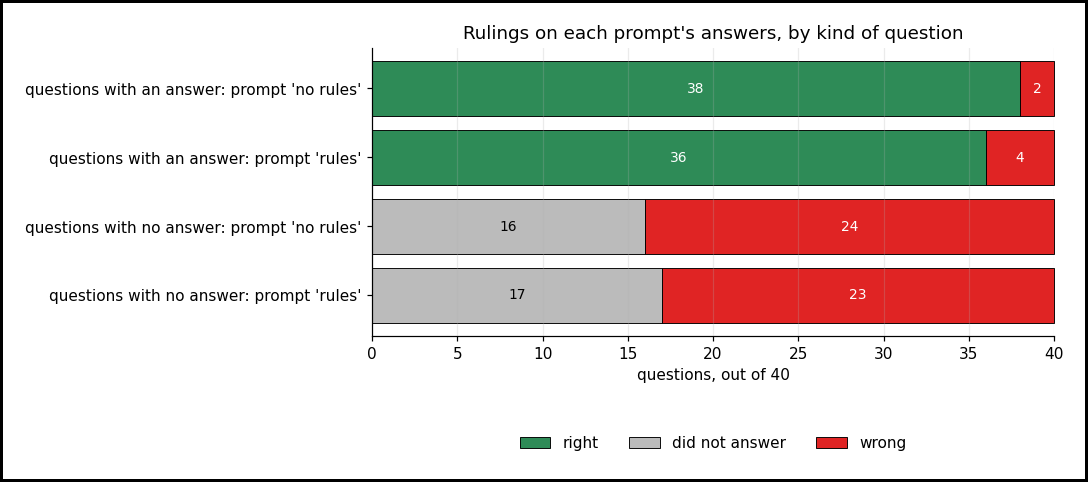

In [12]:
bars = {}
for kind, table in [("with an answer", with_answer), ("with no answer", no_answer)]:
    for name in PROMPTS:
        bars[f"questions {kind}: prompt '{name}'"] = table[name + ": ruling"].value_counts()
bars = pd.DataFrame(bars).T.reindex(columns=["right", "did not answer", "wrong"]).fillna(0).astype(int)
fig, ax = plt.subplots(figsize=(8, 3.4))
left = np.zeros(len(bars))
for ruling_name in bars.columns:
    color, text_color = RULING_COLORS[ruling_name]
    ax.barh(bars.index, bars[ruling_name], left=left, color=color, edgecolor="black", linewidth=0.6, clip_on=False, label=ruling_name)
    for y, (l, v) in enumerate(zip(left, bars[ruling_name])):
        if v:
            ax.text(l + v / 2, y, str(v), ha="center", va="center", color=text_color, fontsize=9)
    left += bars[ruling_name].values
ax.invert_yaxis()
ax.set_xlim(0, SAMPLE)
ax.set_xlabel(f"questions, out of {SAMPLE}")
ax.set_title("Rulings on each prompt's answers, by kind of question")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=3, frameon=False)
ax.grid(axis="y", visible=False)
plt.show()

**Observation:** the kind of question matters more than the prompt: 38 and 36 of 40 answered correctly on the questions with an answer (ruled *right*), against 16 and 17 of 40 on the questions with no answer (ruled *did not answer*). Within each kind, the two prompts' bars differ by 1 or 2 questions. So for this language model, a question whose answer is in no article is the hard case, whichever prompt is used.

## Step 4 of 5: the citations

**Does an answer that cites a chunk take its claim from that chunk?**

**[in real life]** In a test before the system goes live, every answer's square brackets are read, and each number in them is a cited chunk; "[1-5]" cites chunks 1 to 5. Text in brackets that holds no number, such as "[Not enough information]", is not a citation. The table counts, for each prompt and kind of question, the answers that cite, and of those, the answers whose every cited number is a chunk in the prompt.

In [13]:
def cited(answer):
    numbers = set()
    for inside in re.findall(r"\[([\d,\s\-–]+)\]", answer):
        for part in re.split(r"\s*,\s*|\s+", inside.strip()):
            if re.fullmatch(r"\d+[-–]\d+", part):
                low, high = map(int, re.split(r"[-–]", part))
                numbers.update(range(low, high + 1))
            elif part.isdigit():
                numbers.add(int(part))
    return sorted(numbers)


rows = []
for kind, table in [("with an answer", with_answer), ("with no answer", no_answer)]:
    for name in PROMPTS:
        numbers = table[name + ": answer"].map(cited)
        citing = numbers.map(bool)
        valid = [bool(c) and max(c) <= len(r) for c, r in zip(numbers, table["returned"])]
        table[name + ": cited"] = numbers
        rows.append({"questions": kind, "prompt": name, "answers": str(len(table)), "answers that cite": str(citing.sum()),
                     "citing answers: every cited number in the prompt": str(sum(valid))})
print("Answers that cite chunk numbers:")
print()
show(pd.DataFrame(rows))
for n, (_, row) in enumerate(no_answer.iterrows(), start=1):
    c = row["rules: cited"]
    if c and max(c) > len(row["returned"]):
        print()
        print(f"Cites a chunk not in the prompt: question {n} with no answer, prompt 'rules', cites {c}, chunks returned = {len(row['returned'])}")
        print(f"  Words in its chunk [1] = {len(row['returned'][0].split()):,}")
        print(f"  Chunk [1] names the University of Southern California: {'yes' if 'University of Southern California' in row['returned'][0] else 'no'}")

Answers that cite chunk numbers:

questions       prompt    answers  answers that cite  citing answers: every cited number in the prompt
with an answer  no rules       40                  0                                                 0
with an answer  rules          40                 40                                                40
with no answer  no rules       40                  3                                                 3
with no answer  rules          40                 35                                                34

Cites a chunk not in the prompt: question 20 with no answer, prompt 'rules', cites [5], chunks returned = 1
  Words in its chunk [1] = 966
  Chunk [1] names the University of Southern California: yes


**Observation:** with the rules, all 40 answers to the questions with an answer cite, and 35 of the 40 to the questions with no answer. With no rules, 3 of 80 answers cite, unasked. So rule 2 is the rule the language model follows most: asked to cite, it writes chunk numbers, though only whether the answer has one is checked, not whether every sentence has one, as rule 2 asks.

**Observation:** every cited number is a chunk in the prompt but one: question 20 with no answer cites [5], while its search returned 1 chunk: the top chunk alone holds 966 words, over the 400-word limit, so it is returned alone. Its answer's claim, a side fact about the University of Southern California that does not answer the question, is in chunk [1]: the language model took the claim from chunk [1] and made up the number [5].

The next two checks ask whether a citation points to the right material:
- For each right answer from the *rules* prompt, does a cited chunk hold a sentence the dataset lists for the question?
- How many wrong answers to the questions with no answer still cite a chunk?

In [14]:
right_citing = with_answer[(with_answer["rules: ruling"] == "right") & with_answer["rules: cited"].map(bool)]
backed = [any(s in row["returned"][i - 1] for i in row["rules: cited"] if i <= len(row["returned"]) for s in listed_of(row))
          for _, row in right_citing.iterrows()]
print(f"Prompt 'rules', questions with an answer, right answers that cite at least one chunk = {len(right_citing)}")
others = right_citing[[not b for b in backed]]
names = sum(any(row["answer"].rstrip(".").lower() in row["returned"][i - 1].lower() for i in row["rules: cited"])
            for _, row in others.iterrows())
print(f"  citing at least one chunk that holds a listed sentence = {sum(backed)}")
print(f"  citing only chunks that name the correct answer but hold no listed sentence = {names}")
print()
wrong_citing = no_answer[(no_answer["rules: ruling"] == "wrong") & no_answer["rules: cited"].map(bool)]
print(f"Prompt 'rules', questions with no answer, wrong answers = {(no_answer['rules: ruling'] == 'wrong').sum()}")
print(f"  citing at least one chunk = {len(wrong_citing)}")

Prompt 'rules', questions with an answer, right answers that cite at least one chunk = 36
  citing at least one chunk that holds a listed sentence = 32
  citing only chunks that name the correct answer but hold no listed sentence = 4

Prompt 'rules', questions with no answer, wrong answers = 23
  citing at least one chunk = 23


**Observation:** 32 of the 36 right answers cite a chunk that holds a listed sentence: for those 32, the answer was in front of the language model, whatever it knew from training. The other 4 cite chunks that name the correct answer but hold none of the listed sentences. The 4 can still be grounded (supported by their cited chunks): the dataset's list is not the only text that supports an answer. Whether their claims are in their cited chunks is not checked here.

**Observation:** all 23 wrong answers to the questions with no answer cite a chunk. No chunk can hold their answer, because no article holds it. So a citation shows which chunk the language model points to, not that the chunk supports the claim: only reading the chunk tells.

## Step 5 of 5: two answers with their sources

**What does a user see, and can the user tell a grounded answer from a made-up one?**

**[in real life]** A user of a RAG system sees the answer and can open the chunks it cites. The output below prints two answers from the prompt with the rules, each followed by the chunks it cites: first, a right answer to a question with an answer, then a wrong answer to a question with no answer. The two were picked by hand: question 37 for its short answer, and question 12 because its cited chunk is short enough to read.

In [15]:
def show_sources(table, n):
    row = table.iloc[n - 1]
    print(f"Question: {row['query']}")
    print(f"Answer, prompt 'rules': {tidy(row['rules: answer'])}")
    for i in row["rules: cited"]:
        print(f"Chunk [{i}]: {row['returned'][i - 1]}")


show_sources(with_answer, 37)
print()
print("=" * 60)
print()
show_sources(no_answer, 12)

Question: What is the name of the electric pickup truck discussed in TechCrunch as having an uncertain future and believed by Elon Musk, as reported by The Verge, to be potentially safer for occupants and pedestrians than other trucks?
Answer, prompt 'rules': The electric pickup truck discussed is called the Cybertruck. [1] [2] [4]
Chunk [1]: Elon Musk is “highly confident” that the Cybertruck will be safer than other trucks on the road for occupants and pedestrians. Tesla has historically achieved high safety ratings thanks to its underlying architecture, which makes the car more rigid and better protects passengers. The location of the battery in the floor of the vehicle also gives the Model Y and other Tesla vehicles a lower center of gravity, which improves road stability and decreases the chances of a rollover. All four of Tesla’s vehicles, the Model S, X, 3, and Y, have earned five-star ratings from Euro NCAP.
Chunk [2]: The Cybertruck is a steel-clad electric pickup truck made b

**Observation:** in the first answer, chunks [1], [2] and [4] each name the *Cybertruck*, and chunk [1] holds Musk's claim about safety that the question quotes. The answer is grounded: its claim is in the chunks it cites.

**Observation:** in the second answer, chunk [2] names *Nigeria* in a story about StarNews, a different company, and says nothing about M-Pesa or a currency symbol. The answer's claim is not in the chunk it cites.

To a user, the two answers look alike: a claim followed by chunk numbers. Only opening the cited chunk tells a grounded answer from a made-up one.

## Key takeaways
- The prompt holds the numbered chunks, the question and the instructions. With the language model fixed, the analyst decides in part 5, generate, what the prompt says.
- Rule 2, citing, was the rule the language model followed: with it, 40 + 35 = 75 of 80 answers cited chunks, against 3 of 80 without it.
- Rule 3, *"Not enough information"*, did not make the language model decline more often: on the questions whose answer is in no article, both prompts offered a candidate for more than half, the rules changed which questions were declined rather than how many, and some answers offered a candidate and wrote *"Not enough information"* too.
- A citation is not proof: every wrong answer the *rules* prompt gave to a question with no answer cited a chunk. Checking a citation means reading the chunk.
- A program that looks for declining phrases counts an answer that declines and then adds a guess, such as *"likely Brazil"*, as declining. Answers have to be read.
- These counts come from one small language model, llama3.2:3b, and 40 questions of each kind, so they are rough. A larger model may follow rule 3 better: only ruling on its answers can tell.

## Conclusion
With llama3.2:3b, the three rules made the answers cite their chunks, but did not make the model decline more often when the chunks lacked the answer, so every cited answer still has to be checked against the chunks it cites.